# Fase 0 · Entorno y primeros datos

**Objetivo:** comprobar que el entorno funciona y tener un primer contacto con datos de eventos reales.

En este notebook:

1. Exploramos el catálogo de StatsBomb Open Data.
2. Cargamos un partido y vemos cómo se estructura un dato de evento.
3. Separamos **resultado** (goles) de **proceso** (xG) con un mapa de tiros.
4. Vemos qué agregan los *freeze frames* 360.

Datos: [StatsBomb Open Data](https://github.com/statsbomb/open-data), con atribución a StatsBomb.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from mplsoccer import Pitch
from statsbombpy import sb

from futbol.rutas import FIGURAS, asegurar_carpetas

# statsbombpy avisa que no hay credenciales: con datos abiertos no hacen falta.
warnings.filterwarnings("ignore", message="credentials were not supplied")
pd.set_option("display.max_columns", 50)
asegurar_carpetas()

## 1. El catálogo de StatsBomb Open Data

Cada fila es una combinación de competición y temporada. La columna `match_available_360` tiene fecha cuando esa temporada trae *freeze frames* 360.

In [2]:
competiciones = sb.competitions()
print(f"{len(competiciones)} combinaciones de competición y temporada")

(competiciones
 .assign(con_360=competiciones["match_available_360"].notna())
 .groupby(["competition_gender", "con_360"])
 .size()
 .rename("temporadas"))

80 combinaciones de competición y temporada


competition_gender  con_360
female              False      10
                    True        3
male                False      58
                    True        9
Name: temporadas, dtype: int64

In [3]:
# Temporadas con 360: las más ricas para aprender
(competiciones
 .loc[competiciones["match_available_360"].notna(), ["competition_name", "season_name", "competition_gender"]]
 .sort_values(["competition_name", "season_name"])
 .reset_index(drop=True))

,competition_name,season_name,competition_gender
0,1. Bundesliga,2023/2024,male
1,African Cup of Nations,2023,male
2,FIFA World Cup,2022,male
3,La Liga,2020/2021,male
4,Ligue 1,2021/2022,male
5,Ligue 1,2022/2023,male
6,Major League Soccer,2023,male
7,UEFA Euro,2020,male
8,UEFA Euro,2024,male
9,UEFA Women's Euro,2022,female


## 2. Un partido: la final del Mundial 2022

Elegimos la final Argentina–Francia porque tiene 360, prórroga y tanda de penales: muestra casi todos los casos que aparecen en los datos.

In [4]:
mundial = competiciones.query("competition_name == 'FIFA World Cup' and season_name == '2022'").iloc[0]
partidos = sb.matches(competition_id=int(mundial["competition_id"]), season_id=int(mundial["season_id"]))
print(f"{len(partidos)} partidos del Mundial 2022")

final = partidos.query("competition_stage == 'Final'").iloc[0]
final[["match_id", "match_date", "home_team", "away_team", "home_score", "away_score"]]

64 partidos del Mundial 2022


match_id         3869685
match_date    2022-12-18
home_team      Argentina
away_team         France
home_score             3
away_score             3
Name: 27, dtype: object

In [5]:
eventos = sb.events(match_id=int(final["match_id"]))
print(f"{len(eventos):,} eventos y {eventos.shape[1]} columnas")
eventos["type"].value_counts().head(15)

4,407 eventos y 94 columnas


type
Pass              1263
Ball Receipt*     1114
Carry              940
Pressure           361
Ball Recovery      115
Duel                98
Dribble             54
Block               50
Foul Committed      48
Clearance           45
Foul Won            44
Goal Keeper         44
Shot                38
Miscontrol          35
Dispossessed        34
Name: count, dtype: int64

### Anatomía de un evento

Cada fila es una acción con balón o un evento táctico (un cambio, un ajuste de formación). Las columnas clave:

| Columna | Significado |
| --- | --- |
| `type` | Tipo de evento: Pass, Carry, Shot, Pressure… |
| `period`, `minute`, `second`, `timestamp` | Cuándo ocurrió (`period` 5 = tanda de penales) |
| `team`, `player`, `position` | Quién lo hizo |
| `location` | Dónde: [x, y] en una cancha de 120 × 80 |
| `possession`, `possession_team` | A qué posesión pertenece |
| `related_events` | Eventos ligados (por ejemplo, un pase y su recepción) |
| `pass_*`, `shot_*`, `carry_*`… | Atributos propios de cada tipo |

Veamos un tiro con todas sus columnas no vacías:

In [6]:
tiro = eventos[eventos["type"] == "Shot"].iloc[0]
tiro.dropna()

duration                                                        0.94819
id                                 545c2c84-018f-4570-a01c-753823feaeac
index                                                               192
location                                                   [92.4, 30.0]
match_id                                                        3869685
minute                                                                4
period                                                                1
play_pattern                                               Regular Play
player                                              Alexis Mac Allister
player_id                                                       27886.0
position                                           Left Center Midfield
possession                                                           14
possession_team                                               Argentina
possession_team_id                                              

### El sistema de coordenadas

StatsBomb usa una cancha de 120 × 80 unidades, con el origen arriba a la izquierda, y el equipo con el balón siempre ataca hacia la derecha (x = 120). Opta y Wyscout usan 0–100 en ambos ejes. Antes de mezclar proveedores hay que convertir coordenadas; en la fase 1 lo hace `kloppy`.

## 3. Resultado frente a proceso: goles y xG

El xG de StatsBomb (`shot_statsbomb_xg`) es la probabilidad de gol de cada tiro. Excluimos la tanda de penales (`period` 5), que no es parte del juego en curso.

In [7]:
tiros = eventos[(eventos["type"] == "Shot") & (eventos["period"] < 5)].copy()
tiros[["x", "y"]] = pd.DataFrame(tiros["location"].tolist(), index=tiros.index).iloc[:, :2]
tiros["gol"] = tiros["shot_outcome"].eq("Goal")

tiros.groupby("team").agg(
    tiros=("id", "size"),
    goles=("gol", "sum"),
    xG=("shot_statsbomb_xg", "sum"),
).round(2)

,tiros,goles,xG
team,,,
Argentina,20,3,2.76
France,10,3,2.27


Con unos 25 tiros por partido, el azar pesa mucho: un equipo puede ganar con menos xG o perder generando más. Por eso la analítica mide el proceso además del resultado.

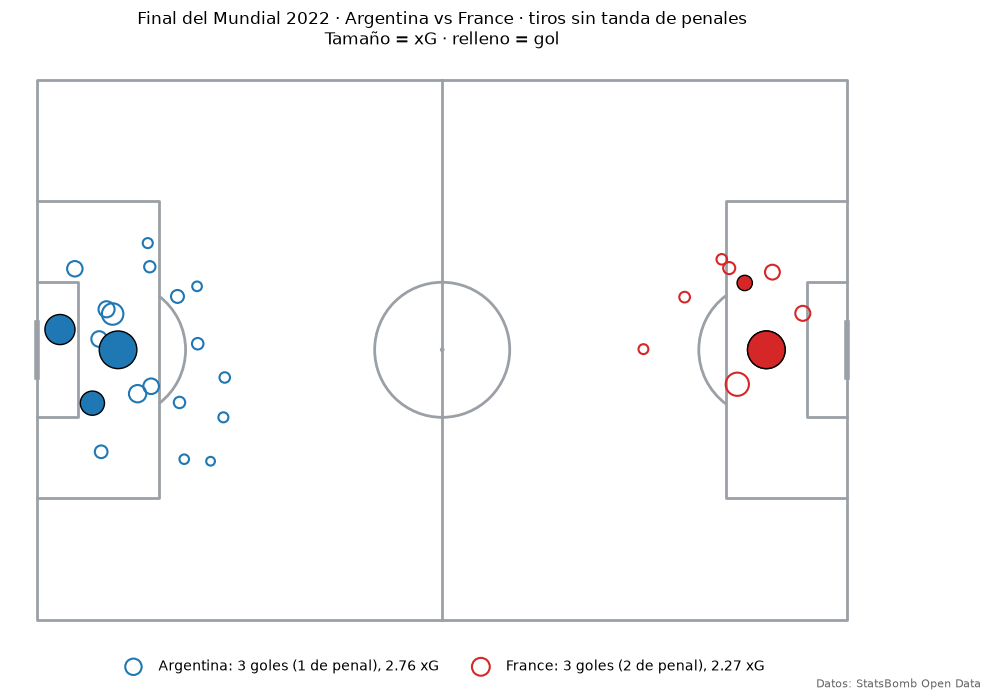

In [8]:
pitch = Pitch(pitch_type="statsbomb", line_color="#9aa0a6", pitch_color="white")
fig, ax = pitch.draw(figsize=(11, 7))

local, visita = final["home_team"], final["away_team"]
colores = {local: "#1f77b4", visita: "#d62728"}

for equipo in (local, visita):
    t = tiros[tiros["team"] == equipo]
    # El local se dibuja atacando hacia la izquierda para ver a ambos equipos en una sola cancha.
    x = 120 - t["x"] if equipo == local else t["x"]
    y = 80 - t["y"] if equipo == local else t["y"]
    tamano = t["shot_statsbomb_xg"] * 900 + 30
    # Los penales caen todos en el mismo punto y se superponen: se informan en la leyenda.
    goles_penal = int((t["gol"] & t["shot_type"].eq("Penalty")).sum())
    pitch.scatter(x[~t["gol"]], y[~t["gol"]], s=tamano[~t["gol"]], ax=ax,
                  facecolors="none", edgecolors=colores[equipo], linewidths=1.5,
                  label=f"{equipo}: {int(t['gol'].sum())} goles ({goles_penal} de penal), "
                        f"{t['shot_statsbomb_xg'].sum():.2f} xG")
    pitch.scatter(x[t["gol"]], y[t["gol"]], s=tamano[t["gol"]], ax=ax,
                  color=colores[equipo], edgecolors="black")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
ax.set_title(f"Final del Mundial 2022 · {local} vs {visita} · tiros sin tanda de penales\n"
             "Tamaño = xG · relleno = gol", fontsize=12)
fig.text(0.99, 0.01, "Datos: StatsBomb Open Data", ha="right", fontsize=8, color="#666")
fig.savefig(FIGURAS / "f0_mapa_tiros_final_mundial_2022.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. *Freeze frames* 360

En las temporadas con 360, cada evento trae además la posición de los jugadores visibles en la imagen de transmisión en ese instante. Es un paso intermedio entre los eventos y el tracking.

In [9]:
frames = sb.frames(match_id=int(final["match_id"]))
print(f"{frames['id'].nunique():,} eventos con freeze frame y {len(frames):,} posiciones de jugadores")
frames.head()

3,683 eventos con freeze frame y 61,451 posiciones de jugadores


,id,visible_area,match_id,teammate,actor,keeper,location
0,f651a6c4-55e3-4e0f-a178-59414ba83d6a,"[8.984968, 80.0, 41.462204, 0.0, 80.340833, 0....",3869685,True,False,False,"[39.216957, 44.778613]"
1,f651a6c4-55e3-4e0f-a178-59414ba83d6a,"[8.984968, 80.0, 41.462204, 0.0, 80.340833, 0....",3869685,True,False,False,"[39.223561, 29.496847]"
2,f651a6c4-55e3-4e0f-a178-59414ba83d6a,"[8.984968, 80.0, 41.462204, 0.0, 80.340833, 0....",3869685,True,False,False,"[42.576673, 67.523741]"
3,f651a6c4-55e3-4e0f-a178-59414ba83d6a,"[8.984968, 80.0, 41.462204, 0.0, 80.340833, 0....",3869685,True,False,False,"[46.54912, 12.613254]"
4,f651a6c4-55e3-4e0f-a178-59414ba83d6a,"[8.984968, 80.0, 41.462204, 0.0, 80.340833, 0....",3869685,True,False,False,"[47.798306, 43.130706]"


## 5. Qué sigue

- **Fase 1:** estandarizar eventos a SPADL con `kloppy` y `socceraction`, calcular métricas por 90 minutos y medir su fiabilidad.
- **Para pensar:** ¿cuántos tiros necesita un jugador para que su diferencia entre goles y xG sea señal y no ruido? Pista: la varianza de una suma de variables de Bernoulli con probabilidades distintas.